# Possession normalization: comparing defensive activity

**Question.** Two teams each make 14 interceptions. One has 30% possession; the other
has 70%. Do those identical counts tell us the same thing?

**Idea in plain words.** The first team spends more of the game without the ball,
so it has more opportunity to defend. We express each team's count at a common
50/50 possession split, keeping the original count alongside it. This gives us
another view of defensive activity; it does not tell us which team defends better.

**Plan.** *Part A* walks through interceptions and three ways to make the adjustment.
*Part B* compares all three statistics, checks the predictions on a later season,
and looks at what changes for UC San Diego.

The 14-interception example is an illustration. All match results below are real
MotherDuck data captured on November 5, 2026: women's Fall 2023–24 for fitting and
2025 for evaluation. One observation is one team in one game.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "possession_analysis").is_dir())
sys.path.insert(0, str(repo))
from possession_analysis import normalize as pn
from possession_analysis import methods, plots

sns.set_theme(style="whitegrid", context="notebook")
GENDER, YEAR, TERM = "female", 2025, "Fall"
TRAIN_YEARS = [2023, 2024]
STAT = "interceptions"  # the stat we walk through in Part A
TEAM = "UC San Diego Tritons"
DB = os.getenv("MOTHERDUCK_DB", "wyscout_dev")
DATA_FILE = os.getenv("POSSESSION_MATCHES_CSV")  # optional multi-season history.csv

## Data

We use each side's reported match possession, rather than its share of passes.
The scope includes played matches in regular Fall season entries, including
nonconference and tournament games. Missing statistics remain coverage gaps.

The models learn from 2023–24, then face 2025 games they were not fitted on.
Each comparison uses the same eligible games for a given statistic.

In [2]:
if DATA_FILE:
    history = pn.load_history_csv(DATA_FILE, GENDER, TRAIN_YEARS + [YEAR], TERM)
else:
    with pn.connect(DB) as con:
        history = pn.load_history(con, GENDER, TRAIN_YEARS + [YEAR], TERM, DB)

experiment = methods.compare_methods(history, TRAIN_YEARS, YEAR)
data = experiment.test
raw = history.loc[history["year"].eq(YEAR)].copy()
deep_dive = data.loc[data[f"common_{STAT}"]].copy()

display(experiment.split.set_index("split")[["years", "matches", "valid_possession_rows"]]
        .rename(columns={"years": "Seasons", "matches": "Games",
                         "valid_possession_rows": "Team-games with usable possession"}))
excluded = len(data) - data["normalization_status"].eq("ok").sum()
print(f"{YEAR}: {excluded:,} team-game rows excluded for missing or invalid statistics/possession.")
print(f"Interception comparisons use {len(deep_dive):,} team-games.")

2025: 606 team-game rows excluded for missing or invalid statistics/possession.
Interception comparisons use 6,260 team-games.


,Seasons,Games,Team-games with usable possession
split,,,
Training,"2023, 2024",6721,12692
Evaluation,2025,3433,6260


# Part A: interceptions, step by step

## A1. See the difference in opportunity

An interception cuts out an opponent's pass. A team that rarely has the ball
has more chances to face those passes. Each dot below is one team's count in one
2025 game; the dashed line marks 50% possession.

Counts generally fall as possession rises, but teams with the same possession
still vary considerably. Possession explains part of the picture.

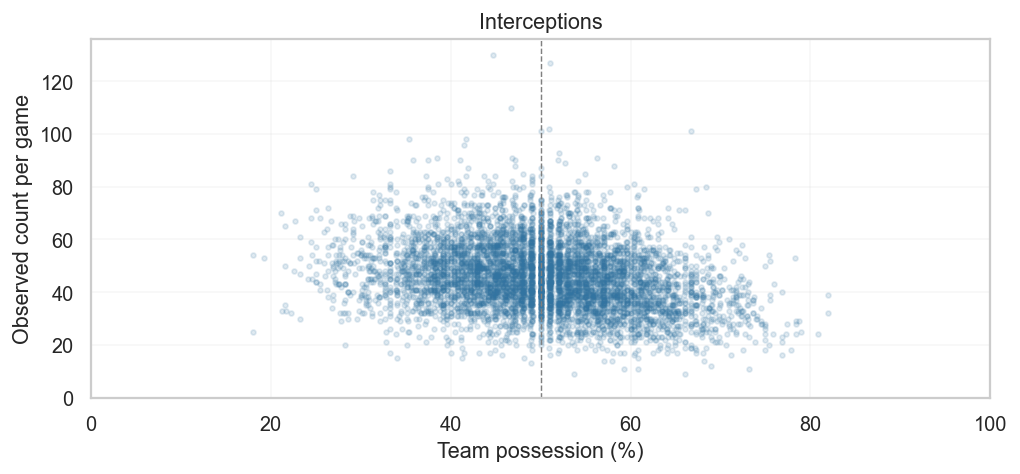

In [3]:
plots.observed(deep_dive, stats=(STAT,))
plt.show()

## A2. Method 1: assume actions grow in proportion to time defending

**Idea.** If a team spends twice as much of the game without the ball, assume it
has twice as many opportunities to make defensive actions.

`50/50 equivalent = observed count × 50 / opponent possession (%)`

In our illustration, Example A faces 70% opponent possession and Example B faces
30%. Applying the same rule to their 14 interceptions gives:

In [4]:
# Illustration only: these are not observed match records.
illustration = pd.DataFrame({
    "match_id": [0, 0], "team_id": [1, 2], "opponent_id": [2, 1],
    "stats_available": [True, True], "opponent_stats_available": [True, True],
    "reported_possession_pct": [30., 70.], "opponent_reported_possession_pct": [70., 30.],
    **{f"total_{stat}": [14, 14] for stat in pn.STATS},
}, index=["Example A", "Example B"])
illustration = pn.normalize(illustration)
display(illustration[["possession_pct", "opponent_possession_pct", "total_interceptions", "p50_interceptions"]]
        .rename(columns={"possession_pct": "Own possession (%)",
                         "opponent_possession_pct": "Opponent possession (%)",
                         "total_interceptions": "Observed", "p50_interceptions": "Fixed 50/50"}).round(2))

,Own possession (%),Opponent possession (%),Observed,Fixed 50/50
Example A,30.0,70.0,14,10.00
Example B,70.0,30.0,14,23.33


Example A's 14 becomes 10, while Example B's becomes 23.33. The fractions are
equivalent counts for comparison, not additional actions that happened. At
50% possession the count stays unchanged.

**Strength:** simple to explain, with an adjustment that follows directly from
the possession split. **Weakness:** the proportional relationship is an assumption.
Tactics, field position and how opponents use the ball also affect defensive activity.

The next plot shows what this assumption does to the real data. Lines show the
median within each possession group; shading covers the middle half of the counts.

Correlation with possession: observed -0.28, fixed 50/50 0.39.


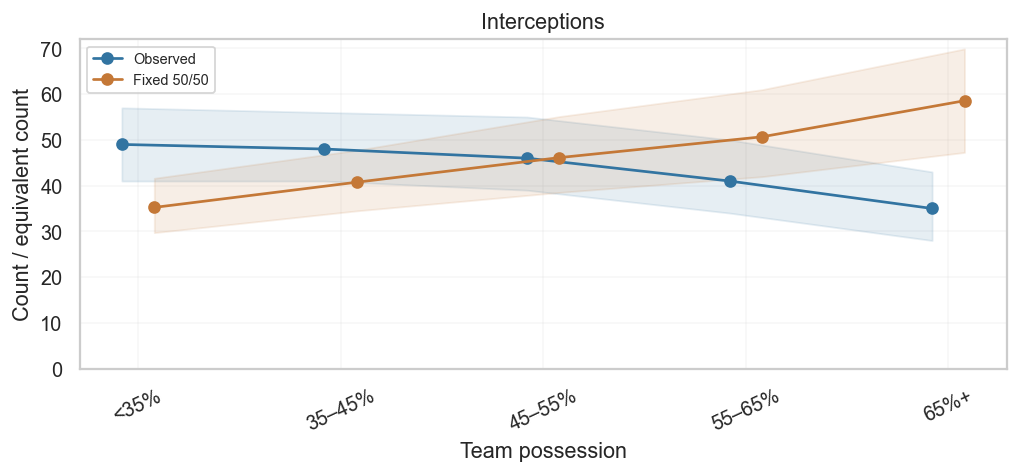

In [5]:
plots.bands(deep_dive, stats=(STAT,))
plt.show()

fixed_check = pn.comparison(deep_dive).set_index("stat").loc[STAT]
print(f"Correlation with possession: observed {fixed_check['raw_possession_rho']:.2f}, "
      f"fixed 50/50 {fixed_check['p50_possession_rho']:.2f}.")

The downward pattern becomes an upward one. This suggests the fixed adjustment
may be too strong. A flat line would not prove success either: team quality and
playing style can legitimately vary with possession.

## A3. Method 2: learn how much adjustment each statistic needs

**Idea.** Keep the fixed formula, but let the earlier seasons tell us how strongly
to apply it. The exponent `alpha` controls the strength:

`50/50 equivalent = observed count × (50 / opponent possession (%)) ** alpha`

- `alpha = 0`: keep the observed count.
- `alpha = 1`: use the full fixed adjustment.
- Between zero and one: make a smaller adjustment in the same direction.

For interceptions the fitted exponent is about **0.365**. Here is what that means
for the same two illustrative teams:

Exponent fitted on 12,692 earlier team-games: 0.365


,Own possession (%),Observed,Fixed 50/50,Learned exponent
Example A,30.0,14,10.00,12.38
Example B,70.0,14,23.33,16.87


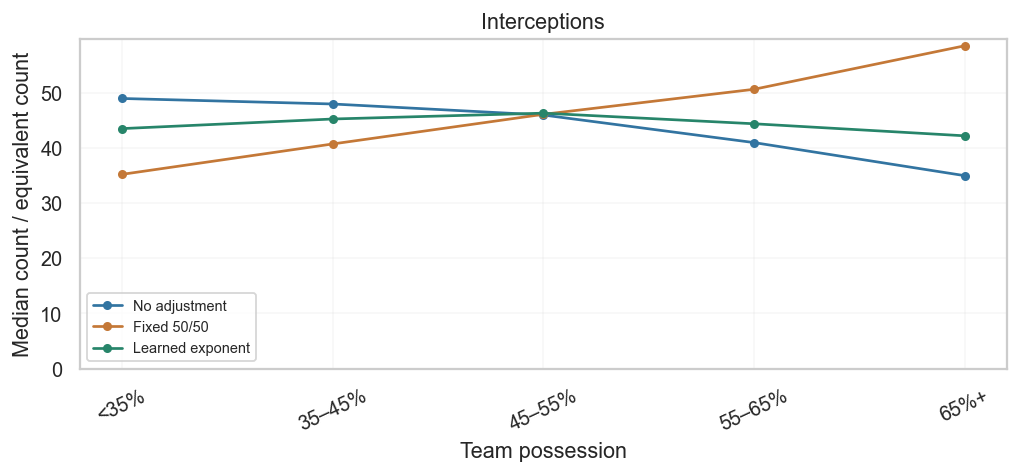

In [6]:
alpha = experiment.power[STAT].alpha
worked = illustration[["possession_pct", "total_interceptions", "p50_interceptions"]].copy()
worked["Learned exponent"] = worked["total_interceptions"] * illustration["normalization_factor"] ** alpha
display(worked.rename(columns={"possession_pct": "Own possession (%)",
                               "total_interceptions": "Observed", "p50_interceptions": "Fixed 50/50"}).round(2))
print(f"Exponent fitted on {experiment.power[STAT].n_train:,} earlier team-games: {alpha:.3f}")

plots.method_bands(deep_dive, methods=("raw", "fixed", "power"), stats=(STAT,))
plt.show()

**Strength:** easy to interpret, learns a different correction for each statistic,
and always stays between the observed count and the fixed equivalent.
**Weakness:** it still uses one possession relationship across teams. If strong
teams tend to have more possession, the fitted relationship can mix that difference
with defensive opportunity.

The exponent is fitted to earlier counts, including zeros. It is not selected
to make the 2025 possession correlation disappear.

## A4. Method 3: estimate the possession effect alongside team and match context

**Idea.** Compare expected counts after accounting for recorded differences between
teams and games. The model uses possession, pre-match team/opponent strength,
home/away status, team identity, competition and the match-duration category.

We ask it twice about the same game: once at the actual possession and once at 50%.
Every other input stays the same.

`50/50 equivalent = observed count × expected count at 50% / expected count at actual possession`

For a real example, take UCSD's highest-possession game in this sample. The table
separates what happened from the model's two estimates:

In [7]:
ucsd = deep_dive.loc[deep_dive["team_name"].eq(TEAM)].sort_values("possession_pct")
if ucsd.empty:
    case = deep_dive.sort_values("possession_pct").iloc[[-1]]
else:
    case = ucsd.iloc[[-1]]
row = case.iloc[0]
fit = experiment.context[STAT]
expected = fit.predict(case)[0]
expected_50 = fit.predict(case.assign(possession_pct=50.))[0]
print(f"{row['team_name']} vs {row['opponent_name']}, {pd.Timestamp(row['date']).date()} (UTC)")
display(pd.Series({
    "Own possession (%)": row["possession_pct"],
    "Observed interceptions": row[f"total_{STAT}"],
    "Expected at actual possession": expected,
    "Expected at 50% possession": expected_50,
    "Multiplier (expected at 50% / expected at actual)": expected_50 / expected,
    "Context-adjusted interceptions": row[f"context50_{STAT}"],
}, name="Value").round(2).to_frame())

UC San Diego Tritons vs UC Riverside Highlanders, 2025-10-17 (UTC)


,Value
Own possession (%),69.80
Observed interceptions,59.00
Expected at actual possession,35.91
Expected at 50% possession,43.81
Multiplier (expected at 50% / expected at actual),1.22
Context-adjusted interceptions,71.98


In this saved example, UCSD made **59 interceptions with 69.8% possession**.
The model's expected counts are about 35.91 at actual possession and 43.81 at 50%.
Their ratio is 1.22, giving **71.98 equivalents**. The fixed method gives 97.68;
the learned exponent gives 70.91.

**Strength:** recorded team and match differences help estimate the possession
relationship. The curve can bend rather than follow one fixed formula.
**Weakness:** the extra flexibility introduces more assumptions. In this run it
also raises some low-possession counts, so it is not a simple correction for
time spent defending.

The curves below show the multiplier directly: one keeps the count, 0.5 halves
it and two doubles it. These are fitted curves, not additional observed games.

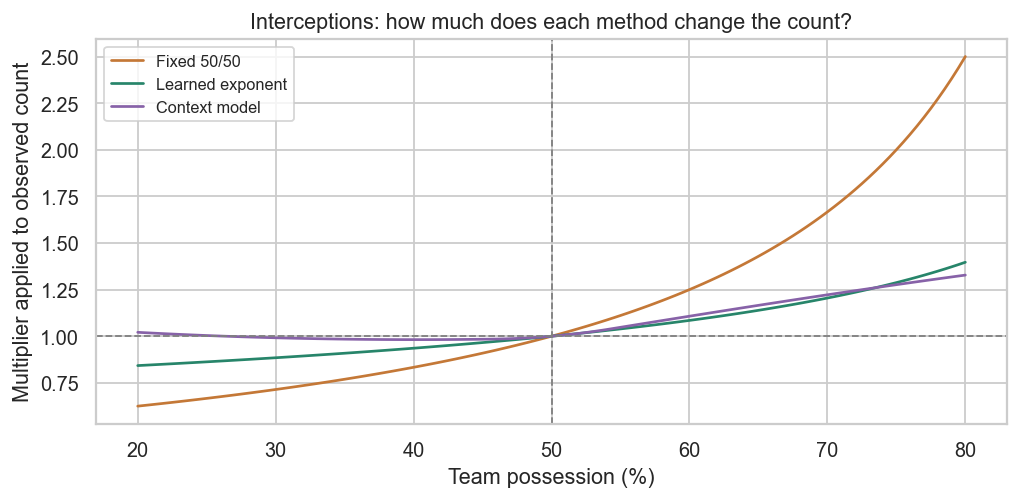

In [8]:
plots.factors(experiment, STAT)
plt.show()

The context model uses a smooth possession curve plus other effects in its
log-mean prediction. Those other effects cancel in the ratio. They influence
how the curve is estimated, but teams at the same possession get the same
multiplier. This version does not learn a separate possession response for each team.

# Part B: all three statistics

## B1. Do the statistics need the same correction?

Repeat the comparison for interceptions, defensive duels and defensive duels won.
The last is a successful subset of the second; they should not be added together
into one defensive score.

,Earlier team-games,Exponent,At 0 or 1?
stat,,,
Interceptions,12692,0.365,False
Defensive duels,12692,0.608,False
Defensive duels won,12692,0.167,False


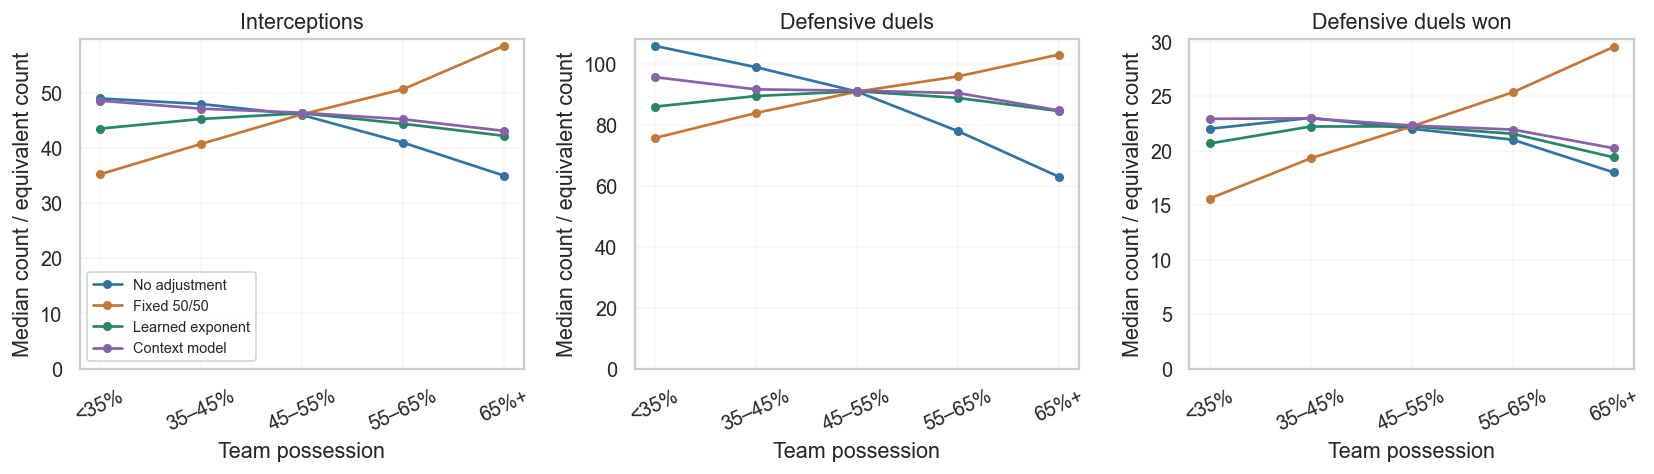

In [9]:
display(experiment.parameters.set_index("stat")[["training_rows", "alpha", "alpha_at_boundary"]]
        .rename(index=pn.LABELS, columns={"training_rows": "Earlier team-games", "alpha": "Exponent",
                                         "alpha_at_boundary": "At 0 or 1?"}).round(3))
plots.method_bands(data)
plt.show()

Defensive duels receive the strongest learned correction; duels won receive the
weakest. Applying the same full correction to every statistic misses that difference.
Each panel uses the same games for its four lines. These lines show medians,
not confidence intervals.

## B2. Which models predict the later games best?

We can check predictions of **actual 2025 counts**. There is no observed answer
for what those games would have produced at 50% possession.

The table reports the average absolute prediction error, in actions per game.
For example, an error of 10 means predictions miss the actual count by ten
actions on average. Lower is better.

The unadjusted reference predicts the earlier seasons' mean. The fixed model
assumes proportional growth with opponent possession. The other models learn the
relationship from the earlier seasons. This is a retrospective check: possession
and duration are known after the game, so it is not a pre-game forecast.

In [10]:
display(methods.score_table(experiment.scores, "mae").round(2))

,No adjustment,Fixed 50/50,Learned exponent,Context model
Statistic,,,,
Interceptions,10.05,10.61,9.63,9.45
Defensive duels,17.89,16.44,15.49,14.90
Defensive duels won,5.38,5.90,5.31,5.16


The context model has the lowest prediction error for all three statistics.
The learned exponent also improves on the fixed method in each case. But the
context model uses more information, so its better predictions do not establish
that its 50/50 equivalents are more accurate.

## B3. What changes for UC San Diego?

First look at two real games: UCSD's lowest and highest possession in this sample.
The fixed formula makes the largest changes; the learned methods give smaller
changes in these examples. Dates are in UTC.

In [11]:
if ucsd.empty:
    print(f"No eligible games for {TEAM} in this scope.")
else:
    examples = ucsd.iloc[[0, -1]].drop_duplicates(["match_id", "team_id"]).copy()
    examples["date"] = pd.to_datetime(examples["date"]).dt.strftime("%Y-%m-%d")
    display(examples[["date", "opponent_name", "possession_pct", "total_interceptions",
                      "p50_interceptions", "power50_interceptions", "context50_interceptions"]]
            .rename(columns={"date": "Date (UTC)", "opponent_name": "Opponent", "possession_pct": "Possession (%)",
                             "total_interceptions": "Observed", "p50_interceptions": "Fixed 50/50",
                             "power50_interceptions": "Learned exponent", "context50_interceptions": "Context model"})
            .set_index("Date (UTC)").round(2))

,Opponent,Possession (%),Observed,Fixed 50/50,Learned exponent,Context model
Date (UTC),,,,,,
2025-09-14,San Francisco Dons,36.7,37.0,29.23,33.95,36.37
2025-10-17,UC Riverside Highlanders,69.8,59.0,97.68,70.91,71.98


Now average each game's equivalents over the season. Each eligible game gets
equal weight. We do not adjust the season total using one average possession value.

In [12]:
team_rows = methods.team_comparison(data, TEAM, min_matches=5)
if team_rows.empty:
    print(f"No {TEAM} summary with at least five eligible games.")
else:
    display(team_rows.set_index("stat").rename(index=pn.LABELS,
            columns={"matches": "Games", **methods.METHODS}).round(2))

,Games,No adjustment,Fixed 50/50,Learned exponent,Context model
stat,,,,,
Interceptions,19,44.74,52.07,47.08,47.80
Defensive duels,19,86.74,99.63,93.99,95.13
Defensive duels won,19,20.63,24.41,21.17,21.65


UCSD's mean interceptions change from **44.74 observed** to **52.07 fixed**,
**47.08 with the learned exponent**, or **47.80 with the context model** over 19 games.
The choice of adjustment materially changes the picture presented to a coach.

## Additional checks

The main analysis uses reported possession. Pass share can give a different
answer because teams do not all pass at the same rate while they have the ball.
The first table measures that difference on games where both are available.

The second table checks model coverage: unfamiliar teams have no learned team
effect, and possession outside the fitting range would require extrapolation.
Input validation, model settings and detailed prediction metrics are documented
in the [module README](../README.md) and exported CSVs.

In [13]:
reported = pn.normalize(raw)
proxy = pn.normalize(raw, source="pass_share")
common = reported["valid_interceptions"] & proxy["valid_interceptions"]
display(pd.Series({
    "Games' team-rows with both measures": int(common.sum()),
    "Mean possession difference (percentage points)":
        (reported.loc[common, "possession_pct"] - proxy.loc[common, "possession_pct"]).abs().mean(),
    "Mean difference in fixed interception equivalents":
        (reported.loc[common, "p50_interceptions"] - proxy.loc[common, "p50_interceptions"]).abs().mean(),
}, name="Value").round(2).to_frame())

checks = []
for stat in pn.STATS:
    d = data.loc[data[f"common_{stat}"]]
    checks.append({"Statistic": pn.LABELS[stat], "Team-games compared": len(d),
                   "Unseen-team rows": int(d["unseen_team"].sum()),
                   "Outside fitting possession range": int(d[f"outside_training_range_{stat}"].sum())})
display(pd.DataFrame(checks).set_index("Statistic"))
print("Rows with missing model context:", int((~data["context_available"]).sum()))

Rows with missing model context: 0


,Value
Games' team-rows with both measures,6260.00
Mean possession difference (percentage points),2.33
Mean difference in fixed interception equivalents,2.36


,Team-games compared,Unseen-team rows,Outside fitting possession range
Statistic,,,
Interceptions,6260,44,0
Defensive duels,6260,44,0
Defensive duels won,6260,44,0


## Takeaways

Based on the saved run (women's Fall 2025, models fitted on 2023–24):

- **Possession gives useful context to defensive counts.** UCSD's 59 interceptions
  against UC Riverside become anywhere from 70.91 to 97.68 equivalents, depending
  on the assumption we make about opportunity. Keep the observed number visible.
- **The fixed method often adjusts too strongly here.** The possession relationship
  flips from negative to positive for all three statistics. That is a warning sign,
  not proof that every remaining relationship should be removed.
- **The learned exponent is the clearest candidate for the next integration test.**
  It makes smaller, stat-specific changes and improves count prediction over the
  fixed method. We have not yet shown that it improves player comparisons.
- **The context model predicts actual counts best.** Keep it as a comparison, with
  its flexible curve and extra assumptions visible. Predicting actual counts and
  estimating a hypothetical 50/50 game are different tasks.
- **Next step:** compare raw and adjusted defensive inputs in the low-minutes
  models using the same later-player-performance target and split. Possession
  adjustment addresses opportunity; low-minutes methods address limited evidence.

The current fits are team-level and cover one evaluation season. Player use needs
validation and ideally possession during each player's actual stints, especially
for substitutes. Score state, territory and tactical roles remain unmeasured.
These are per-game equivalents, not per-90 rates or success percentages, and no
significance tests treating opposing teams as independent observations are used.